In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/drive/MyDrive/beam_data
!wget -c -O /content/drive/MyDrive/beam_data/scenario32.zip "https://www.dropbox.com/scl/fi/dd4iu0epfge6kznf8f6f5/scenario32.zip?rlkey=yt45sfzfpscpv66nivppfk6mc&st=zdjhatv9&dl=1"
!ls -lh /content/drive/MyDrive/beam_data/

--2026-11-06 15:50:52--  https://www.dropbox.com/scl/fi/dd4iu0epfge6kznf8f6f5/scenario32.zip?rlkey=yt45sfzfpscpv66nivppfk6mc&st=zdjhatv9&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.1.18, 2620:100:6016:18::a27d:112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.1.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uccee06ee25a2f84eee7cc403c4b.dl.dropboxusercontent.com/cd/0/inline/DLZ07hRtAKryvixkTRCtWI1wgU8eSyj7i5IEGYEIpbKEScc0NTThbM9CDrks_Vkw2-9RQFsy82Gji_IIzynW1ciGwNhK1ZZOT7xAj4IAqAf6R2fTB-qp98dY7aopwiHDafPtHwUAcmx4u7dQ942lPWgU/file?dl=1# [following]
--2026-11-06 15:50:53--  https://uccee06ee25a2f84eee7cc403c4b.dl.dropboxusercontent.com/cd/0/inline/DLZ07hRtAKryvixkTRCtWI1wgU8eSyj7i5IEGYEIpbKEScc0NTThbM9CDrks_Vkw2-9RQFsy82Gji_IIzynW1ciGwNhK1ZZOT7xAj4IAqAf6R2fTB-qp98dY7aopwiHDafPtHwUAcmx4u7dQ942lPWgU/file?dl=1
Resolving uccee06ee25a2f84eee7cc403c4b.dl.dropboxusercontent.com (uccee06ee25a2f84eee7cc403c4b.dl.dropboxusercontent

In [3]:
!mkdir -p /content/data
!unzip -q /content/drive/MyDrive/beam_data/scenario32.zip -d /content/data
!ls /content/data
!find /content/data -maxdepth 2 -name "*.csv"

scenario32_dev.csv  unit1  unit2
/content/data/scenario32_dev.csv


In [4]:
import pandas as pd
pd.set_option('display.max_colwidth', 120)

CSV = "/content/data/scenario32_dev.csv"
df = pd.read_csv(CSV)

print("Taille :", df.shape)
print("\nColonnes :")
for c in df.columns:
    print("  -", c)
print("\nPremière ligne :")
print(df.iloc[0])

Taille : (3235, 20)

Colonnes :
  - index
  - unit1_rgb
  - unit1_pwr_60ghz
  - unit1_lidar
  - unit1_radar
  - unit1_loc
  - unit2_loc
  - unit1_beam
  - unit1_max_pwr
  - time_stamp
  - seq_index
  - unit2_spd_over_grnd_kmph
  - unit2_num_sats
  - unit2_altitude
  - unit2_geo_sep
  - unit2_mode_fix_type
  - unit2_pdop
  - unit2_hdop
  - unit2_vdop
  - unit2_interpolated_position

Première ligne :
index                                                               1
unit1_rgb                             ./unit1/camera_data/image_1.jpg
unit1_pwr_60ghz                ./unit1/mmWave_data/mmWave_power_1.txt
unit1_lidar                       ./unit1/lidar_data/lidar_data_1.ply
unit1_radar                       ./unit1/radar_data/radar_data_1.npy
unit1_loc                           ./unit1/GPS_data/gps_location.txt
unit2_loc                         ./unit2/GPS_data/GPS_location_1.txt
unit1_beam                                                          3
unit1_max_pwr                         

In [5]:
!ls /content/data/unit1
!ls /content/data/unit1/* | head -40

camera_data  GPS_data  lidar_data  mmWave_data	radar_data
/content/data/unit1/camera_data:
image_1000.jpg
image_1001.jpg
image_1002.jpg
image_1003.jpg
image_1004.jpg
image_1005.jpg
image_1006.jpg
image_1007.jpg
image_1008.jpg
image_1009.jpg
image_100.jpg
image_1010.jpg
image_1011.jpg
image_1012.jpg
image_1013.jpg
image_1014.jpg
image_1015.jpg
image_1016.jpg
image_1017.jpg
image_1018.jpg
image_1019.jpg
image_101.jpg
image_1020.jpg
image_1021.jpg
image_1022.jpg
image_1023.jpg
image_1024.jpg
image_1025.jpg
image_1026.jpg
image_1027.jpg
image_1028.jpg
image_1029.jpg
image_102.jpg
image_1030.jpg
image_1031.jpg
image_1032.jpg
image_1033.jpg
image_1034.jpg
image_1035.jpg


Étape 1.2 : Labels

regarder un fichier de puissance

In [6]:
import numpy as np, os
ROOT = "/content/data"

def full_path(p):
    # Les chemins du CSV sont relatifs : "./unit1/..." -> "/content/data/unit1/..."
    return os.path.join(ROOT, p.replace("./", "", 1))

pwr = np.loadtxt(full_path(df.loc[0, "unit1_pwr_60ghz"]))
print("Forme :", pwr.shape)
print("Argmax (0-63) :", pwr.argmax(), "| unit1_beam du CSV :", df.loc[0, "unit1_beam"])
print("Max :", pwr.max(), "| unit1_max_pwr du CSV :", df.loc[0, "unit1_max_pwr"])

Forme : (64,)
Argmax (0-63) : 2 | unit1_beam du CSV : 3
Max : 0.1746741086244583 | unit1_max_pwr du CSV : 0.174674109


calculer les labels de tous les échantillons et les comparer au CSV

In [7]:
from tqdm import tqdm

powers = np.stack([np.loadtxt(full_path(p)) for p in tqdm(df["unit1_pwr_60ghz"])])
df["beam_label"] = powers.argmax(axis=1)     # label 0..63

diff = (df["unit1_beam"] - df["beam_label"])
print("Décalage CSV - argmax :", diff.value_counts().head())
print("Labels min/max :", df["beam_label"].min(), df["beam_label"].max())
np.save("/content/powers.npy", powers)        # on garde les 64 puissances, utiles plus tard

100%|██████████| 3235/3235 [00:01<00:00, 3085.47it/s]

Décalage CSV - argmax : 1    3235
Name: count, dtype: int64
Labels min/max : 1 61


distribution des labels, utile pour l’article

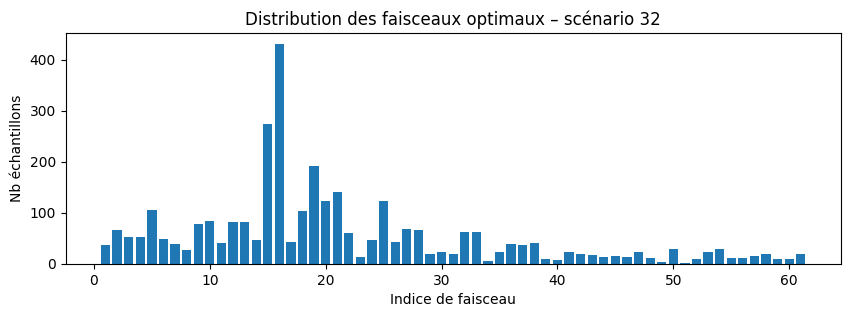

Faisceau le plus fréquent : 16 (13.3%)


In [8]:
import matplotlib.pyplot as plt
counts = df["beam_label"].value_counts().sort_index()
plt.figure(figsize=(10,3))
plt.bar(counts.index, counts.values)
plt.xlabel("Indice de faisceau"); plt.ylabel("Nb échantillons")
plt.title("Distribution des faisceaux optimaux – scénario 32")
plt.savefig("/content/beam_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
print("Faisceau le plus fréquent :", counts.idxmax(), f"({counts.max()/len(df):.1%})")

synchronisation et séquences

In [9]:
df["t"] = pd.to_datetime(df["time_stamp"], format="%H:%M:%S-%f")
dt = df.groupby("seq_index")["t"].diff().dt.total_seconds().dropna()

print("Nombre de séquences :", df["seq_index"].nunique())
print("Échantillons par séquence :\n", df["seq_index"].value_counts().describe())
print(f"Pas temporel médian : {dt.median():.3f} s  (~{1/dt.median():.1f} Hz)")
missing = [p for col in ["unit1_rgb","unit1_radar","unit1_pwr_60ghz"] for p in df[col] if not os.path.exists(full_path(p))]
print("Fichiers manquants :", len(missing))

Nombre de séquences : 15
Échantillons par séquence :
 count     15.000000
mean     215.666667
std      103.013638
min      104.000000
25%      129.500000
50%      184.000000
75%      286.000000
max      405.000000
Name: count, dtype: float64
Pas temporel médian : 0.092 s  (~10.9 Hz)
Fichiers manquants : 0


Étape 1.3 : Split par séquence et splits.csv

chercher un bon découpage d’environ 70/15/15

In [10]:
SEQS = df["seq_index"].unique()
n_per_seq = df["seq_index"].value_counts()

def make_split(seed):
    rng = np.random.default_rng(seed)
    seqs = rng.permutation(SEQS)
    split, cum, total = {}, 0, len(df)
    for s in seqs:
        frac = cum / total
        split[s] = "train" if frac < 0.70 else ("val" if frac < 0.85 else "test")
        cum += n_per_seq[s]
    return split

best = None
for seed in range(500):
    sp = make_split(seed)
    if len(set(sp.values())) < 3:          # il faut les 3 ensembles
        continue
    tmp = df["seq_index"].map(sp)
    fr = tmp.value_counts(normalize=True)
    train_beams = set(df.loc[tmp=="train","beam_label"])
    test_beams  = set(df.loc[tmp=="test","beam_label"])
    unseen = len(test_beams - train_beams)          # faisceaux du test jamais vus en train
    score = abs(fr.get("train",0)-0.70) + abs(fr.get("val",0)-0.15) + abs(fr.get("test",0)-0.15) + 0.05*unseen
    if best is None or score < best[0]:
        best = (score, seed, sp)

score, SEED, split_map = best
df["split"] = df["seq_index"].map(split_map)
print("Seed choisi :", SEED)
print(df["split"].value_counts(), "\n")
print(df.groupby("split")["seq_index"].unique())

Seed choisi : 239
split
train    2265
val       490
test      480
Name: count, dtype: int64 

split
test                                [3, 14]
train    [1, 2, 5, 6, 7, 8, 10, 11, 12, 16]
val                             [4, 13, 17]
Name: seq_index, dtype: object


vérifier qu’il n’y a aucune fuite

In [11]:
tr = set(df.loc[df.split=="train","seq_index"])
va = set(df.loc[df.split=="val","seq_index"])
te = set(df.loc[df.split=="test","seq_index"])
print("Intersections (doivent être vides) :", tr & va, tr & te, va & te)
print("Faisceaux du test absents du train :", sorted(set(df.loc[df.split=="test","beam_label"]) - set(df.loc[df.split=="train","beam_label"])))

Intersections (doivent être vides) : set() set() set()
Faisceaux du test absents du train : []


enregistrer splits.csv

In [12]:
cols = ["index", "seq_index", "split", "beam_label", "unit1_rgb", "unit1_radar", "unit1_lidar", "unit1_pwr_60ghz"]
df[cols].to_csv("/content/drive/MyDrive/beam_data/splits.csv", index=False)
print("Sauvegardé dans Drive (partagé avec ta collègue)")

from google.colab import files
files.download("/content/drive/MyDrive/beam_data/splits.csv")   # pour le mettre aussi dans GitHub

Sauvegardé dans Drive (partagé avec ta collègue)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
!rm -rf /content/repo
!git clone -q https://github.com/nerminecheriaa/beam-prediction-deepsense6g.git /content/repo

import sys; sys.path.insert(0, "/content/repo")
from src.evaluate import topk_accuracy
print("Import OK")

Import OK


In [15]:
train_df = df[df.split == "train"]
test_df  = df[df.split == "test"]

freq = np.bincount(train_df["beam_label"], minlength=64).astype(float)
logits = np.tile(freq, (len(test_df), 1))
print("Baseline 'faisceau le plus fréquent' :", topk_accuracy(logits, test_df["beam_label"].values))

Baseline 'faisceau le plus fréquent' : {'top1': 0.13124999403953552, 'top3': 0.36250001192092896, 'top5': 0.4229166805744171}
